# EE602L – Pattern Recognition and Machine Learning Lab
## Lab 10: Linear Discriminant Analysis and Bayesian Decision Theory

**Name:** Jayesh<br>
**Roll number:** IS24BM008

This notebook has two questions:

* **Question 1 – Linear Discriminant Analysis (LDA)** on the Vehicle Silhouettes dataset (4 vehicle types).
* **Question 2 – Bayesian Decision Theory** on the Breast Cancer Wisconsin dataset (malignant vs. benign).

All core algorithms (scatter matrices, LDA directions, nearest-class-mean classifier, Gaussian Bayes classifiers,
minimum-risk rule, ROC curve) are written with NumPy. scikit-learn is used only for loading data, splitting,
standardising, PCA, the reference LDA model that the sheet asks us to compare against, and the accuracy / F1 /
confusion-matrix helpers.

### Setup
We import the libraries and fix the random seed to 42, so every run gives the same split and the same numbers.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import fetch_openml, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 110

---
# Question 1: Linear Discriminant Analysis (Vehicle Silhouettes)

**Goal.** Each row describes the silhouette of a vehicle with 18 shape measurements (compactness, circularity,
elongatedness, ...). The label is one of four vehicle types: `bus`, `opel`, `saab`, `van`.
LDA looks for directions in this 18-D space along which the classes are **far apart from each other** while each
class stays **tightly packed**. We then classify in that low-dimensional space.

### Q1 – Load the data

In [19]:
vehicle = fetch_openml(name="vehicle", version=1, as_frame=True)

X_vehicle = vehicle.data.to_numpy(dtype=float)     # 846 x 18 feature matrix
y_vehicle = vehicle.target.astype(str).to_numpy()  # class names as plain strings
feature_names = list(vehicle.data.columns)

print("Feature matrix shape:", X_vehicle.shape)
print("Missing values:", vehicle.data.isna().sum().sum())
print("\nSamples per class:")
print(pd.Series(y_vehicle).value_counts().sort_index().to_string())

Feature matrix shape: (846, 18)
Missing values: 0

Samples per class:
bus     218
opel    212
saab    217
van     199


**What this shows.** 846 vehicles, 18 numeric features, no missing values. The four classes have about the same
number of samples (199–218 each), so the data is balanced, and plain accuracy is a fair measure here.

### Q1 – Train/test split and standardisation
* **Stratified 70:30 split** (`random_state=42`): the test set keeps the same class proportions as the full data.
* **StandardScaler** is fitted on the **training set only** (mean 0, standard deviation 1 per feature) and then
  applied to both sets. Fitting it on the test set would leak test information into training.
  The features have very different units and ranges, so without scaling, large-valued features would dominate
  PCA and Euclidean distances.

In [20]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_vehicle, y_vehicle, test_size=0.30, stratify=y_vehicle, random_state=RANDOM_STATE
)

scaler = StandardScaler().fit(X_train_raw)   # learn mean/std from training data only
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

classes = np.unique(y_train)                 # ['bus', 'opel', 'saab', 'van']
print("Training set:", X_train.shape, " Test set:", X_test.shape)
print(pd.DataFrame({"train": pd.Series(y_train).value_counts(),
                    "test": pd.Series(y_test).value_counts()}).loc[classes])

Training set: (592, 18)  Test set: (254, 18)
      train  test
bus     153    65
opel    148    64
saab    152    65
van     139    60


### Q1 – Helper functions
These small functions are used in all parts of Question 1.

* `within_class_scatter`: $S_W = \sum_{k}\sum_{x \in C_k} (x - m_k)(x - m_k)^T$ — how spread out each class is around its own mean.
* `sorted_real_eig`: eigen-decomposition that keeps the **real parts** and sorts eigenvalues **largest first** (as the sheet requires).
  `np.linalg.eig` is used because $S_W^{-1}S_B$ is not symmetric, so it can return complex numbers with tiny imaginary parts from rounding.
* `fisher_criterion`: $J(w) = \dfrac{w^T S_B w}{w^T S_W w}$ — between-class spread divided by within-class spread along $w$. Bigger is better.
* `abs_cosine`: $|\cos\theta| = \dfrac{|u^T v|}{\|u\|\,\|v\|}$. We use the absolute value because $w$ and $-w$ describe the same direction.

In [21]:
def within_class_scatter(X, y):
    # S_W: sum over classes of the scatter of each class around its own mean
    n_features = X.shape[1]
    S_W = np.zeros((n_features, n_features))
    for c in np.unique(y):
        centred = X[y == c] - X[y == c].mean(axis=0)
        S_W += centred.T @ centred
    return S_W


def between_class_scatter(X, y):
    # Multi-class S_B: sum_k N_k (m_k - m)(m_k - m)^T, where m is the overall mean
    overall_mean = X.mean(axis=0)
    n_features = X.shape[1]
    S_B = np.zeros((n_features, n_features))
    for c in np.unique(y):
        X_c = X[y == c]
        diff = (X_c.mean(axis=0) - overall_mean).reshape(-1, 1)
        S_B += len(X_c) * (diff @ diff.T)
    return S_B


def sorted_real_eig(M):
    # Eigen-decomposition keeping real parts, eigenvalues sorted in descending order
    eigvals, eigvecs = np.linalg.eig(M)
    eigvals, eigvecs = eigvals.real, eigvecs.real
    order = np.argsort(eigvals)[::-1]
    return eigvals[order], eigvecs[:, order]


def unit(v):
    return v / np.linalg.norm(v)


def fisher_criterion(w, S_B, S_W):
    return (w @ S_B @ w) / (w @ S_W @ w)


def abs_cosine(u, v):
    return abs(u @ v) / (np.linalg.norm(u) * np.linalg.norm(v))

## Q1(a) Two-class Fisher LDA: bus vs. van

### (a)1. Scatter matrices from bus and van training samples
We keep only the bus and van rows of the (already standardised) training set. For two classes we use the
textbook between-class scatter $S_B = (m_{bus} - m_{van})(m_{bus} - m_{van})^T$, where $m$ is a class mean vector.
$S_B$ is built from a single vector, so its rank is 1.

In [22]:
is_bv_train = np.isin(y_train, ["bus", "van"])
is_bv_test = np.isin(y_test, ["bus", "van"])
X_bv_train, y_bv_train = X_train[is_bv_train], y_train[is_bv_train]
X_bv_test, y_bv_test = X_test[is_bv_test], y_test[is_bv_test]

m_bus = X_bv_train[y_bv_train == "bus"].mean(axis=0)
m_van = X_bv_train[y_bv_train == "van"].mean(axis=0)
mean_diff = m_bus - m_van

S_W_bv = within_class_scatter(X_bv_train, y_bv_train)
S_B_bv = np.outer(mean_diff, mean_diff)

print("Bus / van training samples:", (y_bv_train == "bus").sum(), "/", (y_bv_train == "van").sum())
print("S_W shape:", S_W_bv.shape, "| rank:", np.linalg.matrix_rank(S_W_bv),
      "| condition number: %.3e" % np.linalg.cond(S_W_bv))
print("S_B shape:", S_B_bv.shape, "| rank:", np.linalg.matrix_rank(S_B_bv))

Bus / van training samples: 153 / 139
S_W shape: (18, 18) | rank: 18 | condition number: 1.455e+04
S_B shape: (18, 18) | rank: 1


**Result.** $S_W$ has full rank 18, so it can be inverted. Its condition number (about $1.5\times10^4$) is
moderate: inversion is numerically safe. Some features are strongly correlated, which is why it is not close to 1.
$S_B$ has rank 1, as expected for two classes.

### (a)2. Optimal direction: inverse-scatter method vs. eigenvalue method
* **Inverse-scatter method:** maximising $J(w)$ gives the closed form $w^* \propto S_W^{-1}(m_{bus} - m_{van})$.
* **Eigenvalue method:** $w^*$ is the eigenvector of $S_W^{-1}S_B$ with the largest eigenvalue.

Both should give the same direction, so the absolute cosine similarity should be 1.
Since $S_B$ has rank 1, only **one** eigenvalue should be non-zero, and it should equal
$(m_{bus}-m_{van})^T S_W^{-1}(m_{bus}-m_{van})$.

In [23]:
S_W_bv_inv = np.linalg.inv(S_W_bv)

# Method 1: closed form  w = S_W^{-1} (m_bus - m_van)
w_inverse = unit(S_W_bv_inv @ mean_diff)

# Method 2: leading eigenvector of S_W^{-1} S_B
eigvals_bv, eigvecs_bv = sorted_real_eig(S_W_bv_inv @ S_B_bv)
w_eigen = unit(eigvecs_bv[:, 0])

print("Absolute cosine similarity between the two directions: %.10f" % abs_cosine(w_inverse, w_eigen))
print("Theoretical non-zero eigenvalue (m_bus-m_van)^T S_W^-1 (m_bus-m_van): %.6f"
      % (mean_diff @ S_W_bv_inv @ mean_diff))
print("\nAll %d eigenvalues of S_W^-1 S_B (descending):" % len(eigvals_bv))
for start in range(0, len(eigvals_bv), 4):
    print("   ".join(f"λ{j + 1:<2} = {eigvals_bv[j]: .3e}" for j in range(start, min(start + 4, len(eigvals_bv)))))

Absolute cosine similarity between the two directions: 1.0000000000
Theoretical non-zero eigenvalue (m_bus-m_van)^T S_W^-1 (m_bus-m_van): 0.078037

All 18 eigenvalues of S_W^-1 S_B (descending):
λ1  =  7.804e-02   λ2  =  6.257e-16   λ3  =  3.862e-16   λ4  =  1.334e-16
λ5  =  4.540e-17   λ6  =  4.540e-17   λ7  =  8.269e-18   λ8  =  8.269e-18
λ9  =  1.976e-18   λ10 =  1.727e-18   λ11 =  1.727e-18   λ12 = -4.885e-19
λ13 = -4.885e-19   λ14 = -7.330e-18   λ15 = -7.330e-18   λ16 = -1.115e-17
λ17 = -1.115e-17   λ18 = -5.081e-17


**Result.**
* The two methods give **the same direction**: absolute cosine similarity = 1.0000000000.
* Only **one eigenvalue is non-zero (0.0780)**, and it matches the theoretical value
  $(m_{bus}-m_{van})^T S_W^{-1}(m_{bus}-m_{van}) = 0.0780$. The other 17 eigenvalues are between about
  $10^{-15}$ and $-10^{-17}$. These are zeros up to floating-point rounding (the tiny negative values are also rounding errors).
  This is exactly what rank$(S_B)=1$ predicts.

**Why the two methods agree:** $S_W^{-1}S_B w = S_W^{-1}(m_{bus}-m_{van})\,[(m_{bus}-m_{van})^T w]$. The bracket is just a number,
so $S_W^{-1}S_B w$ always points along $S_W^{-1}(m_{bus}-m_{van})$. The only eigenvector with a non-zero eigenvalue is therefore that vector.

### (a)3. Fisher criterion of three directions, and test-set histograms
We compare three candidate directions (all scaled to unit length):
1. **LDA direction** $w^*$ from (a)2.
2. **Mean-difference direction** $m_{bus} - m_{van}$: separates the class means but ignores the class spread.
3. **First principal component (PC1)** of the bus/van training data: the direction of **largest total variance**, found
   without looking at the labels.

$J(w)$ is computed with the bus/van training scatter matrices. Then we project the **test** bus and van samples onto each
direction and draw class-wise histograms.

In [24]:
pca_bv = PCA(n_components=1).fit(X_bv_train)        # PCA fitted on bus/van training data only
pc1_bv = unit(pca_bv.components_[0])

directions = {
    "LDA (optimal)": w_inverse,
    "Mean difference": unit(mean_diff),
    "PC1 (bus/van)": pc1_bv,
}

fisher_table = pd.DataFrame({
    "Fisher criterion J(w)": [fisher_criterion(w, S_B_bv, S_W_bv) for w in directions.values()],
}, index=directions.keys())
fisher_table["J(w) / J(LDA)"] = fisher_table["Fisher criterion J(w)"] / fisher_table.iloc[0, 0]
fisher_table["|cos| with LDA direction"] = [abs_cosine(w, w_inverse) for w in directions.values()]
display(fisher_table)

,Fisher criterion J(w),J(w) / J(LDA),|cos| with LDA direction
LDA (optimal),0.0780,1.0000,1.0000
Mean difference,0.0058,0.0748,0.2383
PC1 (bus/van),0.0032,0.0407,0.0598


**Result.** The LDA direction has by far the highest Fisher criterion (0.0780). The mean-difference direction reaches only
about 7.5% of it (0.0058), and PC1 only about 4% (0.0032). This is expected, because LDA is *defined* as the maximiser of
$J(w)$, and $J(w^*)$ equals the largest eigenvalue from (a)2.
The absolute values of $J$ are small because $S_W$ is a sum over 292 samples while $S_B$ is a single outer product; only the
comparison between directions matters.
The mean-difference direction is far from the LDA direction ($|\cos| = 0.24$) because it ignores how the features are
correlated inside each class. PC1 is almost perpendicular to it ($|\cos| = 0.06$) because PCA ignores the labels.

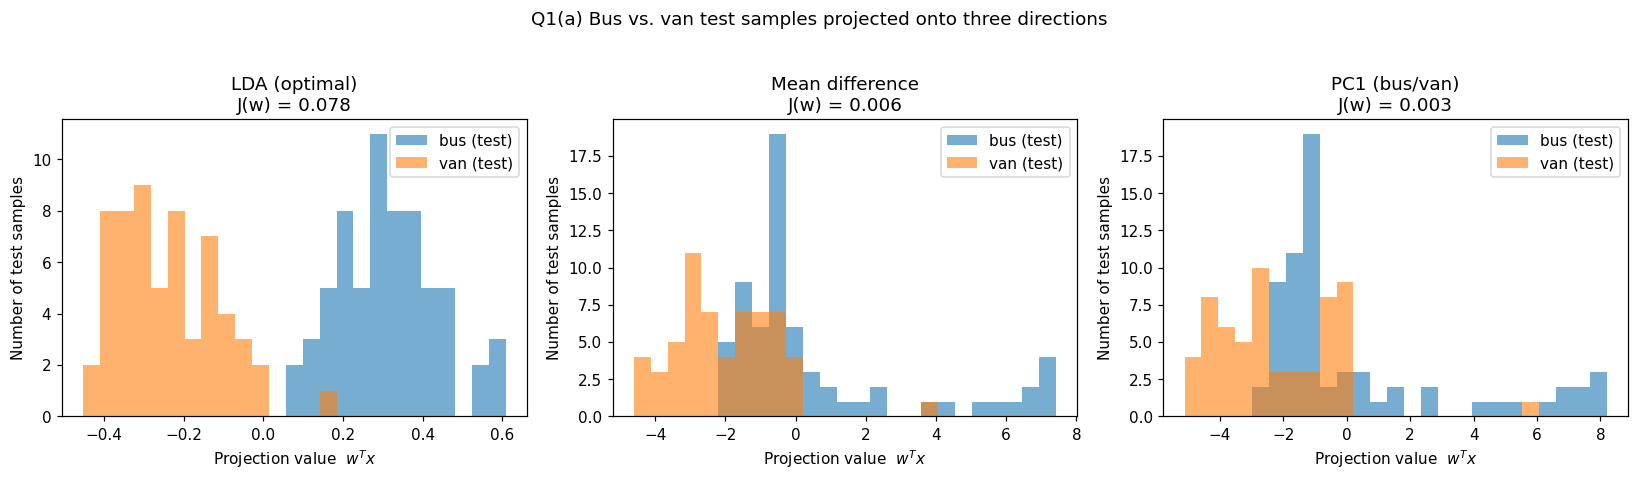

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, w) in zip(axes, directions.items()):
    proj_bus = X_bv_test[y_bv_test == "bus"] @ w
    proj_van = X_bv_test[y_bv_test == "van"] @ w
    bins = np.histogram_bin_edges(np.concatenate([proj_bus, proj_van]), bins=25)
    ax.hist(proj_bus, bins=bins, alpha=0.6, color="tab:blue", label="bus (test)")
    ax.hist(proj_van, bins=bins, alpha=0.6, color="tab:orange", label="van (test)")
    ax.set_title(f"{name}\nJ(w) = {fisher_criterion(w, S_B_bv, S_W_bv):.3f}")
    ax.set_xlabel("Projection value  $w^T x$")
    ax.set_ylabel("Number of test samples")
    ax.legend()
fig.suptitle("Q1(a) Bus vs. van test samples projected onto three directions", y=1.03)
plt.tight_layout()
plt.show()

**What the histograms show (test data).**
* **LDA:** bus and van form two clearly separate groups: vans project to negative values and buses to positive values.
  Only one van falls among the buses, so a single threshold near 0.05 would separate almost all test samples.
* **Mean difference:** the two classes overlap heavily between about −2.5 and 0. The class means are apart, but each class
  is wide along this direction.
* **PC1:** the overlap is about as bad. PC1 follows the direction of largest total spread, which here is mostly variation
  inside the bus class (the long right tail), not the gap between bus and van.

So the training-set ranking of $J(w)$ also holds on unseen test data.

## Q1(b) Multi-class LDA (all four classes)

### (b)1. Scatter matrices from all training data
* $S_W = \sum_k \sum_{x\in C_k}(x-m_k)(x-m_k)^T$ (same function as before, now with 4 classes).
* $S_B = \sum_k N_k (m_k - m)(m_k - m)^T$, where $N_k$ is the class size and $m$ the overall training mean.

In [26]:
S_W = within_class_scatter(X_train, y_train)
S_B = between_class_scatter(X_train, y_train)

print("S_W shape:", S_W.shape, "| rank:", np.linalg.matrix_rank(S_W), "| condition number: %.3e" % np.linalg.cond(S_W))
print("S_B shape:", S_B.shape, "| rank:", np.linalg.matrix_rank(S_B))

S_W shape: (18, 18) | rank: 18 | condition number: 2.184e+04
S_B shape: (18, 18) | rank: 3


**Result.** $S_W$ again has full rank 18 (condition number about $2.2\times10^4$), so $S_W^{-1}$ exists. $S_B$ has rank 3 = number
of classes − 1, as the theory says.

### (b)2. Eigenvalues of $S_W^{-1}S_B$
The four class-mean differences $m_k - m$ add up to zero (weighted by $N_k$), so they span at most
$K-1 = 3$ dimensions. So $S_B$ has rank 3, and $S_W^{-1}S_B$ can have at most 3 non-zero eigenvalues.
An eigenvalue counts as "meaningfully non-zero" if it is larger than $10^{-6}\times$ the largest eigenvalue.

In [27]:
eigvals, eigvecs = sorted_real_eig(np.linalg.inv(S_W) @ S_B)

print("Five largest eigenvalues:")
for i, val in enumerate(eigvals[:5], start=1):
    print(f"  lambda_{i} = {val:.6e}")

threshold = 1e-6 * eigvals[0]
n_nonzero = int(np.sum(eigvals > threshold))
print(f"\nThreshold (1e-6 x largest eigenvalue) = {threshold:.3e}")
print("Number of meaningfully non-zero eigenvalues:", n_nonzero)
print("Number of classes - 1:", len(classes) - 1)
print("Equal?", n_nonzero == len(classes) - 1)

Five largest eigenvalues:
  lambda_1 = 2.414444e+00
  lambda_2 = 2.111436e+00
  lambda_3 = 1.317990e-01
  lambda_4 = 5.793705e-14
  lambda_5 = 7.638336e-15

Threshold (1e-6 x largest eigenvalue) = 2.414e-06
Number of meaningfully non-zero eigenvalues: 3
Number of classes - 1: 3
Equal? True


**Result.** The three largest eigenvalues are 2.414, 2.111 and 0.132. The 4th and 5th are about $2\times10^{-14}$, which is
numerically zero. Using the threshold $10^{-6}\times 2.414 = 2.4\times10^{-6}$, exactly **3 eigenvalues are meaningfully non-zero**,
which equals $K-1 = 4-1 = 3$. ✔

Each eigenvalue is the Fisher ratio (between-class spread ÷ within-class spread) along its direction. LD1 and LD2 are
strong discriminants. LD3 is much weaker (0.13), but as part (c) shows, it still helps.

### (b)3. Project onto the top three discriminants and compare with scikit-learn
We take the eigenvectors of the 3 largest eigenvalues as the columns of $W$ (each scaled to unit length) and project
with $Z = XW$. Then we fit scikit-learn's `LinearDiscriminantAnalysis` (default settings) on the same standardised
training data and compare each of our directions with the matching column of its `scalings_` attribute.
The lengths of the vectors differ between the two implementations, but the **directions** should agree, so we use
absolute cosine similarity.

In [28]:
W_lda = eigvecs[:, :3] / np.linalg.norm(eigvecs[:, :3], axis=0)   # 18 x 3, unit-length columns
Z_train_lda = X_train @ W_lda
Z_test_lda = X_test @ W_lda
print("Projected training data:", Z_train_lda.shape, "| projected test data:", Z_test_lda.shape)

sk_lda = LinearDiscriminantAnalysis().fit(X_train, y_train)
sk_scalings = sk_lda.scalings_[:, :3]

comparison = pd.DataFrame({
    "our eigenvalue": eigvals[:3],
    "|cos(ours, sklearn scalings_)|": [abs_cosine(W_lda[:, i], sk_scalings[:, i]) for i in range(3)],
}, index=["LD1", "LD2", "LD3"])
display(comparison)

Projected training data: (592, 3) | projected test data: (254, 3)


,our eigenvalue,"|cos(ours, sklearn scalings_)|"
LD1,2.4144,1.0
LD2,2.1114,1.0
LD3,0.1318,1.0


**Result.** All three of our directions have absolute cosine similarity 1.0 with the first three columns of scikit-learn's
`scalings_`. Our NumPy implementation finds **exactly the same discriminant directions** as the library. The vectors
differ only in length and sign: scikit-learn scales its directions so that the within-class variance along each one is 1,
while ours have unit length.

## Q1(c) Classification and visualisation

### (c)1. Nearest-class-mean classifier in five feature spaces
**Nearest-class-mean (NCM):** compute the mean of each class in the training data; give a test point the label of the
closest mean (Euclidean distance). It has no parameters to tune, so the only thing that changes between experiments
is the **feature space**:

| Feature space | How test points are mapped |
|---|---|
| Standardised features | all 18 standardised features |
| LDA-1 / LDA-2 / LDA-3 | projection on the top 1, 2 or 3 LDA directions from (b) |
| PCA-3 | first 3 principal components, PCA fitted on the training set |

In [29]:
def ncm_fit(Z, y):
    # returns the class labels and one mean vector per class
    labels = np.unique(y)
    means = np.array([Z[y == c].mean(axis=0) for c in labels])
    return labels, means


def ncm_predict(Z, labels, means):
    # Euclidean distance from every sample to every class mean -> pick the closest
    distances = np.linalg.norm(Z[:, None, :] - means[None, :, :], axis=2)
    return labels[np.argmin(distances, axis=1)]


pca3 = PCA(n_components=3).fit(X_train)     # PCA on the full standardised training set

feature_spaces = {
    "Standardised features (18-D)": (X_train, X_test),
    "LDA, 1 discriminant": (Z_train_lda[:, :1], Z_test_lda[:, :1]),
    "LDA, 2 discriminants": (Z_train_lda[:, :2], Z_test_lda[:, :2]),
    "LDA, 3 discriminants": (Z_train_lda, Z_test_lda),
    "PCA, 3 components": (pca3.transform(X_train), pca3.transform(X_test)),
}

rows, predictions = [], {}
for name, (Z_tr, Z_te) in feature_spaces.items():
    labels, means = ncm_fit(Z_tr, y_train)
    y_pred = ncm_predict(Z_te, labels, means)
    predictions[name] = y_pred
    rows.append({"Feature space": name,
                 "Dimensions": Z_tr.shape[1],
                 "Test accuracy": accuracy_score(y_test, y_pred),
                 "Macro F1-score": f1_score(y_test, y_pred, average="macro")})

print("PCA-3 explained variance ratio:", np.round(pca3.explained_variance_ratio_, 4),
      "(total %.4f)" % pca3.explained_variance_ratio_.sum())

PCA-3 explained variance ratio: [0.521  0.1676 0.1093] (total 0.7980)


### (c)2. Results table, confusion matrix and 2-D plots

In [30]:
results_q1 = pd.DataFrame(rows).set_index("Feature space")
display(results_q1)

,Dimensions,Test accuracy,Macro F1-score
Feature space,,,
Standardised features (18-D),18,0.4567,0.4365
"LDA, 1 discriminant",1,0.6417,0.6215
"LDA, 2 discriminants",2,0.7598,0.7568
"LDA, 3 discriminants",3,0.8150,0.8149
"PCA, 3 components",3,0.4094,0.3848


**Result.**
* **LDA with 3 discriminants is the best feature space:** 81.5% accuracy and macro-F1 0.815, using only 3 numbers per vehicle.
* Accuracy improves steadily with more discriminants: 64.2% (1) → 76.0% (2) → 81.5% (3). LD1 alone cannot separate all four
  classes, and each extra direction adds information.
* **The raw 18-D standardised space does poorly (45.7%)** and **PCA-3 is the worst (40.9%)**, even though PCA-3 keeps 79.8% of
  the total variance. This low accuracy is real, not a bug. Euclidean NCM treats every direction as equally important and
  ignores how the features are correlated within a class. A large part of the variance in this data is spread
  *within* each class (the same vehicle type looks different from different viewing angles). PCA keeps exactly those high-variance directions, so the class
  means end up close together compared with the spread. LDA instead picks directions where the class means are far apart
  *relative to* the within-class spread, and that is what a nearest-mean classifier needs.
* Macro-F1 is close to accuracy in every row, because the classes are balanced and no single class is ignored.

In [31]:
cm_lda3 = confusion_matrix(y_test, predictions["LDA, 3 discriminants"], labels=classes)
display(pd.DataFrame(cm_lda3,
                     index=[f"Actual: {c}" for c in classes],
                     columns=[f"Predicted: {c}" for c in classes]))
print("Per-class recall (LDA-3):",
      {c: round(float(cm_lda3[i, i] / cm_lda3[i].sum()), 3) for i, c in enumerate(classes)})

,Predicted: bus,Predicted: opel,Predicted: saab,Predicted: van
Actual: bus,62,1,1,1
Actual: opel,2,44,16,2
Actual: saab,2,15,45,3
Actual: van,1,0,3,56


Per-class recall (LDA-3): {'bus': 0.954, 'opel': 0.688, 'saab': 0.692, 'van': 0.933}


**Result.** Bus (62/65 correct, recall 0.954) and van (56/60, recall 0.933) are recognised very well. Almost all errors are
**opel ↔ saab confusions**: 16 opels predicted as saab and 15 saabs predicted as opel (recall about 0.69 for both).
This makes sense: Opel and Saab are both ordinary passenger cars with very similar silhouettes, while buses and vans have
clearly different shapes.

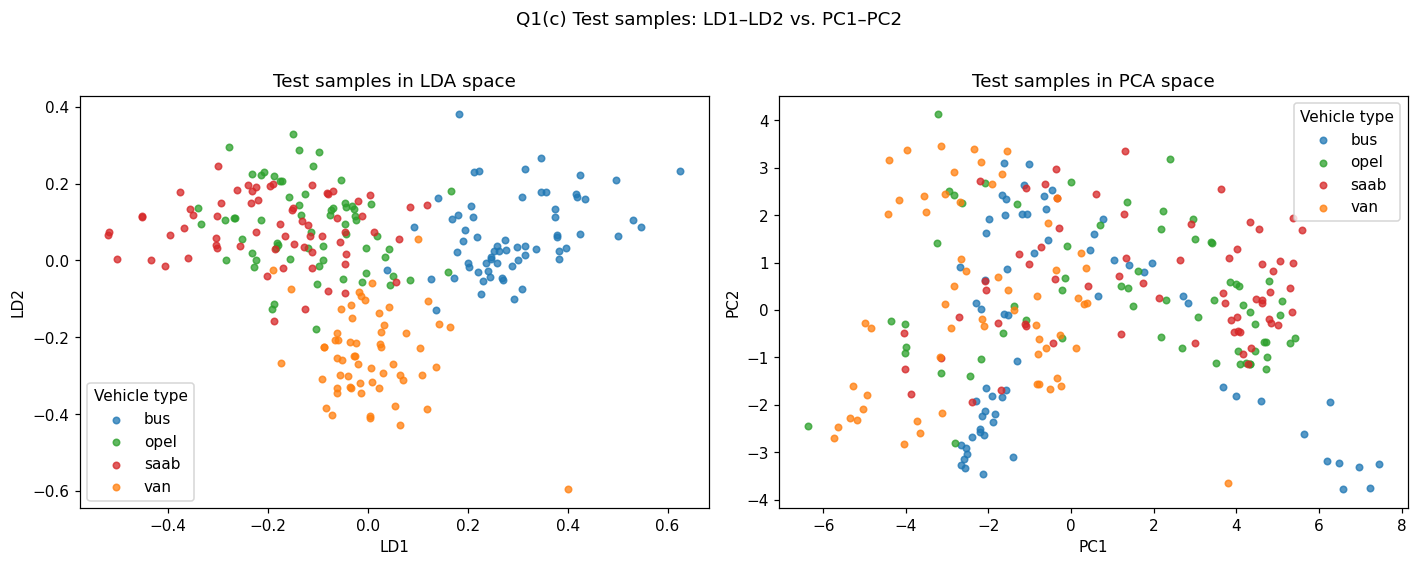

In [32]:
Z_test_pca = feature_spaces["PCA, 3 components"][1]
colours = {"bus": "tab:blue", "opel": "tab:green", "saab": "tab:red", "van": "tab:orange"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, Z, title, xlab, ylab in [
    (axes[0], Z_test_lda, "Test samples in LDA space", "LD1", "LD2"),
    (axes[1], Z_test_pca, "Test samples in PCA space", "PC1", "PC2"),
]:
    for c in classes:
        ax.scatter(Z[y_test == c, 0], Z[y_test == c, 1], s=18, alpha=0.75, color=colours[c], label=c)
    ax.set_title(title)
    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)
    ax.legend(title="Vehicle type")
fig.suptitle("Q1(c) Test samples: LD1–LD2 vs. PC1–PC2", y=1.02)
plt.tight_layout()
plt.show()

**What the plots show.**
* **LD1–LD2:** buses form a group on the right (large LD1), vans a group at the bottom (negative LD2), and opel and saab
  share one overlapping cloud at the top left. This matches the confusion matrix: the opel/saab overlap is where the errors
  come from. LD3 (not shown here) mainly separates opel from saab: opel↔saab confusions drop from 45 test samples with
  LDA-2 to 31 with LDA-3. This explains most of the jump from 76.0% to 81.5%.
* **PC1–PC2:** all four classes are mixed together. PCA does not use the labels, so its top two directions are not
  chosen to separate the classes. This matches the low PCA-3 accuracy.

### Question 1 – Conclusions
1. The two-class Fisher direction from the closed form $S_W^{-1}(m_1-m_2)$ and from the eigenvalue problem are identical
   ($|\cos| = 1$), and $S_W^{-1}S_B$ has exactly one non-zero eigenvalue (0.0780), as rank($S_B$) = 1 predicts.
2. LDA gives a much larger Fisher criterion than the mean-difference direction (about 13× larger) or PC1 (about 25× larger),
   and on the test set it separates bus from van almost perfectly while the other two directions overlap heavily.
3. Four-class LDA has exactly $K-1 = 3$ meaningfully non-zero eigenvalues, and our directions match scikit-learn's `scalings_` exactly.
4. For nearest-class-mean classification, the 3-D LDA space (81.5% accuracy) is far better than the full 18-D standardised
   space (45.7%) or a 3-D PCA space (40.9%). Supervised dimensionality reduction (LDA) keeps class information.
   Unsupervised reduction (PCA) keeps variance, and variance is not the same thing as class separation.
5. The remaining errors are mostly opel vs. saab, two car types whose silhouettes are genuinely very similar.

---
# Question 2: Bayesian Decision Theory (Breast Cancer Wisconsin)

**Goal.** Decide whether a tumour is **malignant** (class 1, the positive class) or **benign** (class 2) from four
measurements: *worst radius, worst texture, worst smoothness, worst concave points*. Missing a malignant tumour
(a false negative) is much worse than a false alarm, which is why part (c) uses unequal losses.

Each class is modelled with a multivariate Gaussian $p(x\mid\omega_k)=\mathcal N(x;\mu_k,\Sigma_k)$.
Bayes' rule then gives the posterior $P(\omega_k\mid x) = \dfrac{p(x\mid\omega_k)P(\omega_k)}{\sum_j p(x\mid\omega_j)P(\omega_j)}$.

### Q2 – Load data, recode labels, split
In scikit-learn's version `target = 0` means malignant and `target = 1` means benign. We recode to
**1 = malignant, 2 = benign** as the sheet asks. Features are used in their original units (the sheet does not ask
for scaling, and Gaussian classifiers with full covariance matrices handle different units on their own).

In [33]:
cancer = load_breast_cancer(as_frame=True)
FEATURES_4 = ["worst radius", "worst texture", "worst smoothness", "worst concave points"]
FEATURES_2 = ["worst radius", "worst concave points"]
MALIGNANT, BENIGN = 1, 2
CLASS_ORDER = [MALIGNANT, BENIGN]               # confusion-matrix order: malignant, then benign
CLASS_NAME = {MALIGNANT: "malignant", BENIGN: "benign"}

X_bc = cancer.data[FEATURES_4].to_numpy()
y_bc = np.where(cancer.target.to_numpy() == 0, MALIGNANT, BENIGN)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_bc, y_bc, test_size=0.30, stratify=y_bc, random_state=RANDOM_STATE
)
idx_2 = [FEATURES_4.index(f) for f in FEATURES_2]   # columns of the two-feature model

print("Training:", Xc_train.shape, " Test:", Xc_test.shape)
print("Training counts  -> malignant:", (yc_train == MALIGNANT).sum(), " benign:", (yc_train == BENIGN).sum())
print("Test counts      -> malignant:", (yc_test == MALIGNANT).sum(), " benign:", (yc_test == BENIGN).sum())

Training: (398, 4)  Test: (171, 4)
Training counts  -> malignant: 148  benign: 250
Test counts      -> malignant: 64  benign: 107


### Q2 – Estimate priors, means and covariances; check the covariance rule
From the **training set only**:
* prior $P(\omega_k) = N_k / N$,
* mean $\mu_k$ = average of class-$k$ rows,
* covariance $\Sigma_k$ = `np.cov` with its default normalisation (divide by $N_k - 1$),
* shared covariance $\Sigma = P(\omega_1)\Sigma_1 + P(\omega_2)\Sigma_2$ (prior-weighted average).

**Covariance rule.** The condition number $\kappa(\Sigma)=\lambda_{max}/\lambda_{min}$ tells us how close a matrix is to
being singular. A huge $\kappa$ makes $\Sigma^{-1}$ numerically unreliable. If any of the six matrices below has
$\kappa > 10^6$, we add $10^{-6} I$ to **every** covariance matrix used in parts (a)–(c).

In [34]:
def estimate_gaussian_params(X, y):
    # priors, means and covariance matrices (np.cov default: divide by N_k - 1), plus the shared covariance
    priors, means, covs = {}, {}, {}
    for k in CLASS_ORDER:
        X_k = X[y == k]
        priors[k] = len(X_k) / len(X)
        means[k] = X_k.mean(axis=0)
        covs[k] = np.cov(X_k, rowvar=False)
    shared_cov = priors[MALIGNANT] * covs[MALIGNANT] + priors[BENIGN] * covs[BENIGN]
    return priors, means, covs, shared_cov


priors, means_4, covs_4, shared_4 = estimate_gaussian_params(Xc_train, yc_train)
_, means_2, covs_2, shared_2 = estimate_gaussian_params(Xc_train[:, idx_2], yc_train)

cond_table = pd.DataFrame({
    "Condition number (before regularisation)": [
        np.linalg.cond(covs_4[MALIGNANT]), np.linalg.cond(covs_4[BENIGN]), np.linalg.cond(shared_4),
        np.linalg.cond(covs_2[MALIGNANT]), np.linalg.cond(covs_2[BENIGN]), np.linalg.cond(shared_2)],
}, index=["4-feature  Σ_malignant", "4-feature  Σ_benign", "4-feature  Σ_shared",
          "2-feature  Σ_malignant", "2-feature  Σ_benign", "2-feature  Σ_shared"])
display(cond_table.map(lambda v: f"{v:.4e}"))

REGULARISE = bool((cond_table.iloc[:, 0] > 1e6).any())
print("Any condition number > 1e6?", REGULARISE)

if REGULARISE:
    ridge_4, ridge_2 = 1e-6 * np.eye(4), 1e-6 * np.eye(2)
    covs_4 = {k: cov + ridge_4 for k, cov in covs_4.items()}
    covs_2 = {k: cov + ridge_2 for k, cov in covs_2.items()}
    shared_4, shared_2 = shared_4 + ridge_4, shared_2 + ridge_2
    print("Regularisation APPLIED: 1e-6 * I added to every covariance matrix.")
else:
    print("Regularisation NOT applied: covariance matrices are used as estimated.")

print("\nPriors: P(malignant) = %.4f, P(benign) = %.4f" % (priors[MALIGNANT], priors[BENIGN]))
display(pd.DataFrame(means_4, index=FEATURES_4).rename(columns=CLASS_NAME).rename_axis("class mean"))

,Condition number (before regularisation)
4-feature Σ_malignant,1.4029e+05
4-feature Σ_benign,1.3536e+05
4-feature Σ_shared,1.2254e+05
2-feature Σ_malignant,1.0182e+04
2-feature Σ_benign,3.7090e+03
2-feature Σ_shared,6.9349e+03


Any condition number > 1e6? False
Regularisation NOT applied: covariance matrices are used as estimated.

Priors: P(malignant) = 0.3719, P(benign) = 0.6281


,malignant,benign
class mean,,
worst radius,21.1803,13.3576
worst texture,29.4819,23.6463
worst smoothness,0.1451,0.1246
worst concave points,0.1853,0.0726


**Result.** The largest condition number is about $1.40\times10^5$ (4-feature malignant covariance). All six are **below $10^6$**,
so by the rule in the sheet **regularisation is not applied**. All covariance matrices are used exactly as estimated by `np.cov`.
The condition numbers are fairly large because the features have very different scales: *worst radius* varies in units of
about 5, while *worst smoothness* varies in units of about 0.02.

The class means already show the pattern: malignant tumours have a larger radius (21.2 vs 13.4) and many more concave points
(0.185 vs 0.073). Priors: P(malignant) = 0.372, P(benign) = 0.628.

## Q2(a) Minimum-error Gaussian classifiers

### (a)1. Three classifiers
* **Prior-only:** ignores $x$ and always picks the class with the larger prior.
* **Quadratic (QDA-type):** each class has its own $\Sigma_k$. The boundary $\{x : P(\omega_1|x)=P(\omega_2|x)\}$ is a quadratic surface.
* **Linear (LDA-type):** both classes use the shared $\Sigma$. The $x^T\Sigma^{-1}x$ terms cancel, so the boundary is a hyperplane.

All three use the minimum-error rule: choose the class with the largest $\log p(x|\omega_k) + \log P(\omega_k)$.
The Gaussian log-density is written by hand:
$\log \mathcal N(x;\mu,\Sigma) = -\tfrac12\big[d\log 2\pi + \log|\Sigma| + (x-\mu)^T\Sigma^{-1}(x-\mu)\big]$.

In [35]:
def gaussian_log_pdf(X, mean, cov):
    # log N(x; mean, cov) for every row of X
    d = len(mean)
    diff = X - mean
    mahal_sq = np.einsum("ij,jk,ik->i", diff, np.linalg.inv(cov), diff)   # (x-mu)^T cov^-1 (x-mu)
    _, log_det = np.linalg.slogdet(cov)
    return -0.5 * (d * np.log(2 * np.pi) + log_det + mahal_sq)


class GaussianBayesClassifier:
    # Two-class Gaussian Bayes classifier: one mean and one covariance per class, plus priors

    def __init__(self, priors, means, covs):
        self.priors, self.means, self.covs = priors, means, covs

    def log_likelihoods(self, X):
        # column 0: log p(x | malignant), column 1: log p(x | benign)
        return np.column_stack([gaussian_log_pdf(X, self.means[k], self.covs[k]) for k in CLASS_ORDER])

    def log_joint(self, X):
        return self.log_likelihoods(X) + np.log([self.priors[k] for k in CLASS_ORDER])

    def posterior(self, X):
        # Bayes' theorem, computed in log-space for numerical safety (log-sum-exp trick)
        log_joint = self.log_joint(X)
        log_evidence = log_joint.max(axis=1, keepdims=True)
        log_evidence = log_evidence + np.log(np.exp(log_joint - log_evidence).sum(axis=1, keepdims=True))
        return np.exp(log_joint - log_evidence)

    def log_likelihood_ratio(self, X):
        # log [ p(x | malignant) / p(x | benign) ]
        ll = self.log_likelihoods(X)
        return ll[:, 0] - ll[:, 1]

    def predict(self, X):
        return np.array(CLASS_ORDER)[np.argmax(self.log_joint(X), axis=1)]


def prior_only_predict(X, priors):
    return np.full(len(X), max(priors, key=priors.get))


quadratic_4 = GaussianBayesClassifier(priors, means_4, covs_4)
linear_4 = GaussianBayesClassifier(priors, means_4, {k: shared_4 for k in CLASS_ORDER})
print("Prior-only classifier always predicts:", CLASS_NAME[max(priors, key=priors.get)])

Prior-only classifier always predicts: benign


### (a)2. Posterior probabilities of the quadratic classifier
For each test sample $P(\omega_1|x) + P(\omega_2|x)$ must be exactly 1 (up to floating-point rounding).

In [36]:
posterior_q4 = quadratic_4.posterior(Xc_test)
posterior_sums = posterior_q4.sum(axis=1)
print("All", len(posterior_sums), "test posteriors sum to one:", np.allclose(posterior_sums, 1.0))
print("Largest |sum - 1| over the test set: %.3e" % np.abs(posterior_sums - 1).max())

display(pd.DataFrame(posterior_q4[:5], columns=["P(malignant | x)", "P(benign | x)"])
        .assign(**{"sum": posterior_sums[:5], "actual": [CLASS_NAME[k] for k in yc_test[:5]]})
        .rename_axis("test sample"))

All 171 test posteriors sum to one: True
Largest |sum - 1| over the test set: 2.220e-16


,P(malignant | x),P(benign | x),sum,actual
test sample,,,,
0,0.9991,0.0009,1.0,malignant
1,0.0053,0.9947,1.0,benign
2,0.0039,0.9961,1.0,benign
3,0.9999,0.0001,1.0,malignant
4,0.3790,0.6210,1.0,malignant


**Result.** For all 171 test samples the two posteriors add up to 1. The largest deviation is $3.3\times10^{-16}$, which is
floating-point rounding. This must happen by construction: Bayes' theorem divides each $p(x|\omega_k)P(\omega_k)$ by their sum
$p(x)$. Sample 4 is an example of an uncertain case: it is actually malignant but gets P(malignant) = 0.38, so the
minimum-error rule calls it benign.

### (a)3. Test-set evaluation
Malignant is the positive class:
* **TPR** (sensitivity) = TP / (TP + FN) = fraction of malignant tumours caught.
* **FPR** = FP / (FP + TN) = fraction of benign tumours wrongly flagged as malignant.
* **Missed malignant** = FN = malignant tumours predicted benign (the costly error).

Confusion matrices: rows = actual class, columns = predicted class, order malignant then benign.

In [37]:
LOSS = np.array([[0, 1],     # decide malignant: actual malignant -> 0, actual benign -> 1 (false alarm)
                 [10, 0]])   # decide benign:    actual malignant -> 10 (missed), actual benign -> 0


def evaluate(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_ORDER)
    tp, fn = cm[0]
    fp, tn = cm[1]
    decision_idx = np.where(y_pred == MALIGNANT, 0, 1)
    actual_idx = np.where(y_true == MALIGNANT, 0, 1)
    metrics = {"Accuracy": (tp + tn) / cm.sum(),
               "TPR": tp / (tp + fn),
               "FPR": fp / (fp + tn),
               "Missed malignant (FN)": fn,
               "Average loss": LOSS[decision_idx, actual_idx].mean()}
    return cm, metrics


def show_cm(cm, title):
    print(title)
    display(pd.DataFrame(cm, index=["Actual: malignant", "Actual: benign"],
                         columns=["Predicted: malignant", "Predicted: benign"]))


predictions_a = {
    "Prior-only": prior_only_predict(Xc_test, priors),
    "Quadratic (separate Σ_k)": quadratic_4.predict(Xc_test),
    "Linear (shared Σ)": linear_4.predict(Xc_test),
}

summary_a = {}
for name, y_pred in predictions_a.items():
    cm, metrics = evaluate(yc_test, y_pred)
    show_cm(cm, f"Confusion matrix – {name}")
    summary_a[name] = metrics

summary_a = pd.DataFrame(summary_a).T.drop(columns="Average loss")
summary_a["Missed malignant (FN)"] = summary_a["Missed malignant (FN)"].astype(int)
display(summary_a)

Confusion matrix – Prior-only


,Predicted: malignant,Predicted: benign
Actual: malignant,0,64
Actual: benign,0,107


Confusion matrix – Quadratic (separate Σ_k)


,Predicted: malignant,Predicted: benign
Actual: malignant,60,4
Actual: benign,6,101


Confusion matrix – Linear (shared Σ)


,Predicted: malignant,Predicted: benign
Actual: malignant,57,7
Actual: benign,0,107


,Accuracy,TPR,FPR,Missed malignant (FN)
Prior-only,0.6257,0.0000,0.0000,64
Quadratic (separate Σ_k),0.9415,0.9375,0.0561,4
Linear (shared Σ),0.9591,0.8906,0.0000,7


**Result.**
* **Prior-only:** always predicts benign, so accuracy = 107/171 = 62.6%, but TPR = 0 and **all 64 malignant tumours are missed**.
  This is the baseline that any useful classifier must beat. It shows that accuracy alone can hide a dangerous classifier.
* **Quadratic:** accuracy 94.2%, TPR 0.938, FPR 0.056, **4 malignant missed**.
* **Linear:** accuracy 95.9% (slightly higher), FPR 0 (no false alarms), but TPR 0.891 and **7 malignant missed**.

So the linear model has slightly higher accuracy here, while the quadratic model catches more malignant tumours. With only
171 test samples, a difference of 3 tumours is small, so we should not over-read the accuracy ranking. For screening, the
quadratic model's lower miss count is the more important property.

## Q2(b) Decision boundaries and the effect of priors

### (b)1. Two-feature classifiers: decision regions and Mahalanobis contours
We rebuild both classifiers with only **worst radius** and **worst concave points** so that we can draw them in 2-D.
On a fine grid we colour each point by its predicted class (decision regions), draw the decision boundary (black line),
plot the test samples, and draw curves of **constant Mahalanobis distance**
$d_M(x) = \sqrt{(x-\mu_k)^T\Sigma_k^{-1}(x-\mu_k)} = 1, 2, 3$ around each class mean.
Each model uses its own covariances: QDA uses $\Sigma_1,\Sigma_2$; the linear model uses the shared $\Sigma$ for both classes.

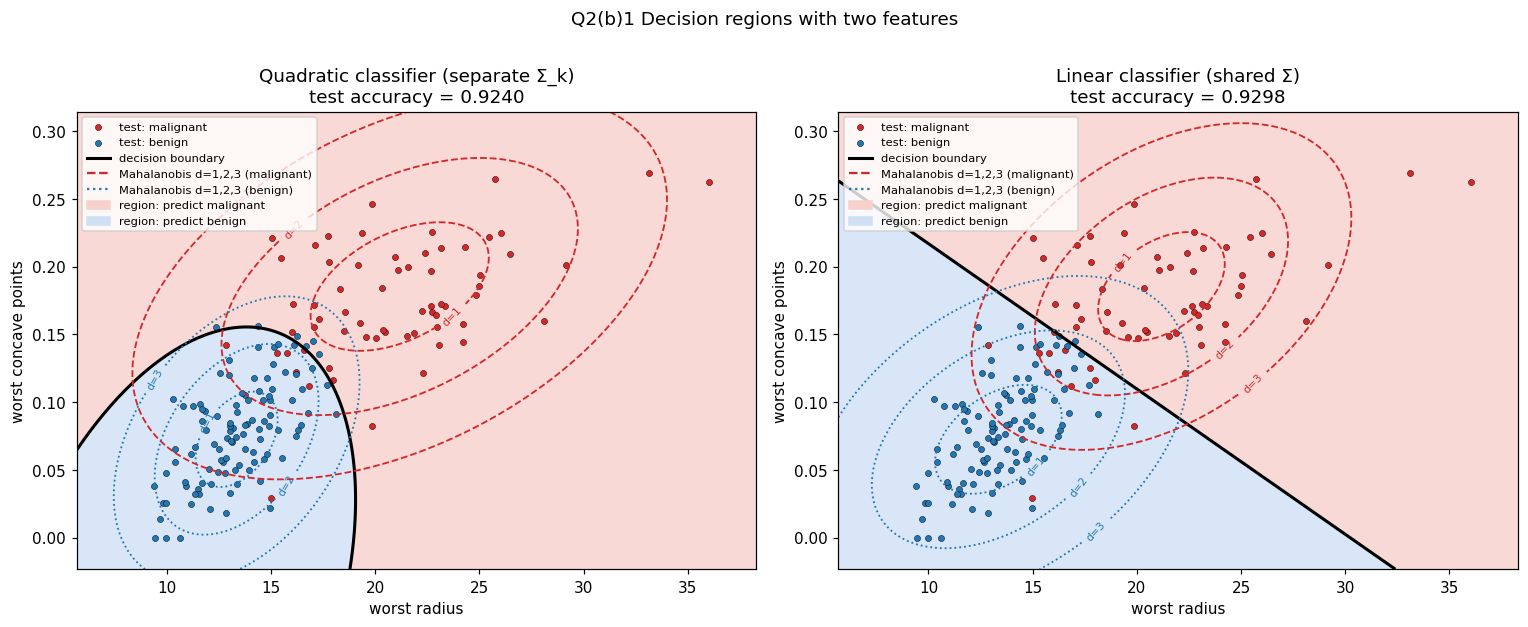

,Accuracy,TPR,FPR,Missed malignant (FN)
"Quadratic, 2 features",0.9240,0.8906,0.0561,7
"Linear, 2 features",0.9298,0.8281,0.0093,11


In [38]:
Xc2_train, Xc2_test = Xc_train[:, idx_2], Xc_test[:, idx_2]
quadratic_2 = GaussianBayesClassifier(priors, means_2, covs_2)
linear_2 = GaussianBayesClassifier(priors, means_2, {k: shared_2 for k in CLASS_ORDER})

# grid covering the training and test data
all_2 = np.vstack([Xc2_train, Xc2_test])
pad = 0.08 * (all_2.max(axis=0) - all_2.min(axis=0))
g0 = np.linspace(all_2[:, 0].min() - pad[0], all_2[:, 0].max() + pad[0], 400)
g1 = np.linspace(all_2[:, 1].min() - pad[1], all_2[:, 1].max() + pad[1], 400)
G0, G1 = np.meshgrid(g0, g1)
grid = np.column_stack([G0.ravel(), G1.ravel()])

CLASS_COLOUR = {MALIGNANT: "tab:red", BENIGN: "tab:blue"}


def mahalanobis(X, mean, cov):
    diff = X - mean
    return np.sqrt(np.einsum("ij,jk,ik->i", diff, np.linalg.inv(cov), diff))


def plot_test_points(ax):
    for k in CLASS_ORDER:
        pts = Xc2_test[yc_test == k]
        ax.scatter(pts[:, 0], pts[:, 1], s=16, color=CLASS_COLOUR[k], edgecolor="k", linewidth=0.3,
                   label=f"test: {CLASS_NAME[k]}")


fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, model, title in [(axes[0], quadratic_2, "Quadratic classifier (separate Σ_k)"),
                         (axes[1], linear_2, "Linear classifier (shared Σ)")]:
    region = (model.predict(grid) == MALIGNANT).reshape(G0.shape)
    ax.contourf(G0, G1, region, levels=[-0.5, 0.5, 1.5], colors=["#cfe0f5", "#f7d0cc"], alpha=0.8)
    score = (model.log_joint(grid) @ np.array([1, -1])).reshape(G0.shape)   # >0 means malignant
    ax.contour(G0, G1, score, levels=[0], colors="k", linewidths=2)
    for k, style in [(MALIGNANT, "--"), (BENIGN, ":")]:
        d_m = mahalanobis(grid, model.means[k], model.covs[k]).reshape(G0.shape)
        cs = ax.contour(G0, G1, d_m, levels=[1, 2, 3], colors=CLASS_COLOUR[k], linestyles=style, linewidths=1.2)
        ax.clabel(cs, fmt=lambda v: f"d={v:.0f}", fontsize=7)
    plot_test_points(ax)
    acc = accuracy_score(yc_test, model.predict(Xc2_test))
    ax.set_title(f"{title}\ntest accuracy = {acc:.4f}")
    ax.set_xlabel("worst radius")
    ax.set_ylabel("worst concave points")
    handles, labels = ax.get_legend_handles_labels()
    handles += [plt.Line2D([], [], color="k", lw=2),
                plt.Line2D([], [], color="tab:red", ls="--"), plt.Line2D([], [], color="tab:blue", ls=":"),
                plt.Rectangle((0, 0), 1, 1, color="#f7d0cc"), plt.Rectangle((0, 0), 1, 1, color="#cfe0f5")]
    labels += ["decision boundary", "Mahalanobis d=1,2,3 (malignant)", "Mahalanobis d=1,2,3 (benign)",
               "region: predict malignant", "region: predict benign"]
    ax.legend(handles, labels, fontsize=7.5, loc="upper left")
fig.suptitle("Q2(b)1 Decision regions with two features", y=1.01)
plt.tight_layout()
plt.show()

summary_b1 = pd.DataFrame({name: evaluate(yc_test, m.predict(Xc2_test))[1]
                           for name, m in [("Quadratic, 2 features", quadratic_2),
                                           ("Linear, 2 features", linear_2)]}).T
display(summary_b1.drop(columns="Average loss").astype({"Missed malignant (FN)": int}))

**What the plots show.**
* **Quadratic:** the boundary is a **curve**. The malignant class has a larger, more spread-out covariance (bigger red ellipses)
  than the benign class, so the benign region is a closed, egg-shaped area around the benign cluster, and everything far
  from it counts as malignant.
* **Linear:** the boundary is a **straight line**. Both classes use the same shared covariance, so their Mahalanobis ellipses
  have the same shape and orientation and differ only in their centre.
* The ellipses point up and to the right because the two features are positively correlated: bigger tumours tend to have more concave points.
* With only two features both models do slightly worse than with four (quadratic 92.4%, linear 93.0%). The misclassified
  points lie in the overlap zone around radius 15–18, where the two classes mix.

### (b)2. Linear classifier: estimated priors vs. equal priors (0.5 / 0.5)
We keep the same means and the same shared covariance and change **only the priors** used in the decision rule.
For the linear model the boundary is $w^T x + b = 0$ with
$w = \Sigma^{-1}(\mu_1-\mu_2)$ and $b = -\tfrac12(\mu_1^T\Sigma^{-1}\mu_1 - \mu_2^T\Sigma^{-1}\mu_2) + \log\dfrac{P(\omega_1)}{P(\omega_2)}$.
Only $b$ depends on the priors, so changing them **shifts the line parallel to itself**.

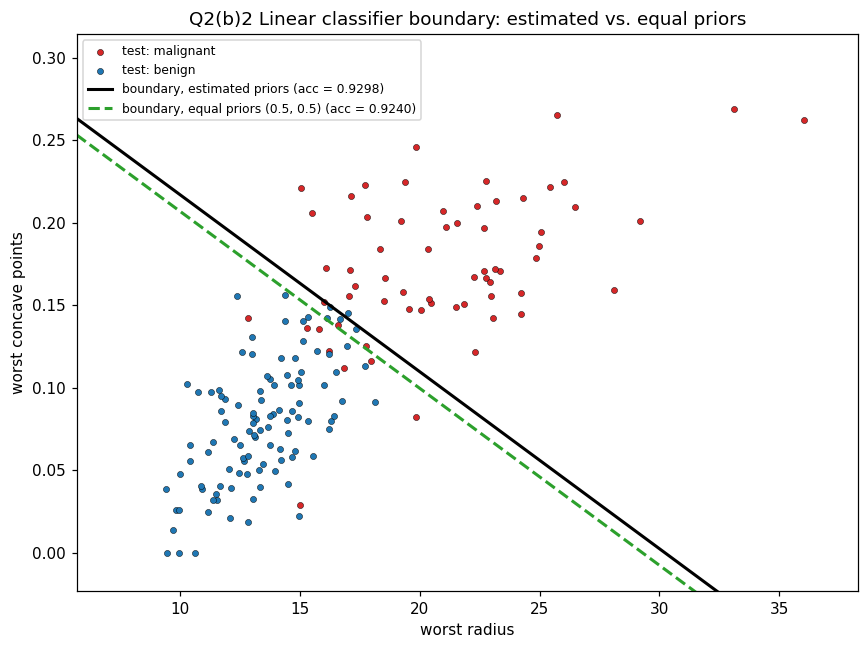

,P(malignant),bias b,Accuracy,TPR,FPR,Missed malignant (FN)
estimated priors,0.3719,-16.8959,0.9298,0.8281,0.0093,11
"equal priors (0.5, 0.5)",0.5000,-16.3716,0.9240,0.8750,0.0467,8


Weight vector w (same for both): [ 0.5589 52.1224]


In [39]:
equal_priors = {MALIGNANT: 0.5, BENIGN: 0.5}
linear_2_equal = GaussianBayesClassifier(equal_priors, means_2, {k: shared_2 for k in CLASS_ORDER})

shared_inv = np.linalg.inv(shared_2)
w_lin = shared_inv @ (means_2[MALIGNANT] - means_2[BENIGN])
b_base = -0.5 * (means_2[MALIGNANT] @ shared_inv @ means_2[MALIGNANT] - means_2[BENIGN] @ shared_inv @ means_2[BENIGN])

fig, ax = plt.subplots(figsize=(8, 6))
plot_test_points(ax)
x_line = np.array([g0.min(), g0.max()])
rows_b2 = {}
for label, pri, colour, style in [("estimated priors", priors, "k", "-"),
                                  ("equal priors (0.5, 0.5)", equal_priors, "tab:green", "--")]:
    b = b_base + np.log(pri[MALIGNANT] / pri[BENIGN])
    y_line = -(w_lin[0] * x_line + b) / w_lin[1]          # solve w0*x + w1*y + b = 0 for y
    model = GaussianBayesClassifier(pri, means_2, {k: shared_2 for k in CLASS_ORDER})
    metrics = evaluate(yc_test, model.predict(Xc2_test))[1]
    rows_b2[label] = {"P(malignant)": pri[MALIGNANT], "bias b": b, **metrics}
    ax.plot(x_line, y_line, color=colour, ls=style, lw=2,
            label=f"boundary, {label} (acc = {metrics['Accuracy']:.4f})")
ax.set_xlim(g0.min(), g0.max())
ax.set_ylim(g1.min(), g1.max())
ax.set_title("Q2(b)2 Linear classifier boundary: estimated vs. equal priors")
ax.set_xlabel("worst radius")
ax.set_ylabel("worst concave points")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

summary_b2 = pd.DataFrame(rows_b2).T.drop(columns="Average loss")
summary_b2["Missed malignant (FN)"] = summary_b2["Missed malignant (FN)"].astype(int)
display(summary_b2)
print("Weight vector w (same for both):", np.round(w_lin, 4))

**Result.** The weight vector $w$ is the same in both cases, so the two boundaries are **parallel**. Only the bias changes,
by $\log(0.5/0.5) - \log(0.372/0.628) = 0.524$. With equal priors the malignant class gets more prior weight than before
(0.5 instead of 0.372), so the boundary moves **towards the benign cluster** (down-left in the plot), and more points are
labelled malignant:
* missed malignant tumours drop from 11 to 8 (TPR 0.828 → 0.875),
* false alarms rise from 1 to 5 (FPR 0.009 → 0.047),
* accuracy drops slightly, from 93.0% to 92.4%.

This is expected: the estimated priors match how often each class actually appears in the data, so they give the
minimum-error boundary. Changing the priors trades one kind of error for the other.

## Q2(c) Minimum-risk classification

### (c)1. Threshold and decision rule
Let $\lambda_{ij}$ = loss of deciding class $i$ when the true class is $j$:
$\lambda_{11}=0,\ \lambda_{12}=1$ (false alarm), $\lambda_{21}=10$ (missed malignant), $\lambda_{22}=0$.

The conditional risks are $R(\alpha_1|x) = \lambda_{11}P(\omega_1|x)+\lambda_{12}P(\omega_2|x)$ and
$R(\alpha_2|x) = \lambda_{21}P(\omega_1|x)+\lambda_{22}P(\omega_2|x)$. Choosing malignant when
$R(\alpha_1|x) < R(\alpha_2|x)$ and using Bayes' theorem gives

$$\Lambda(x)=\frac{p(x\mid\omega_1)}{p(x\mid\omega_2)} \;>\; \theta_{risk}=\frac{\lambda_{12}-\lambda_{22}}{\lambda_{21}-\lambda_{11}}\cdot\frac{P(\omega_2)}{P(\omega_1)} .$$

With 0-1 loss this becomes the minimum-error threshold $\theta_{error} = P(\omega_2)/P(\omega_1)$.
We use the four-feature quadratic classifier's likelihoods.

In [40]:
lam = {"11": LOSS[0, 0], "12": LOSS[0, 1], "21": LOSS[1, 0], "22": LOSS[1, 1]}
theta_error = priors[BENIGN] / priors[MALIGNANT]
theta_risk = (lam["12"] - lam["22"]) / (lam["21"] - lam["11"]) * priors[BENIGN] / priors[MALIGNANT]

print("P(malignant) = %.4f, P(benign) = %.4f" % (priors[MALIGNANT], priors[BENIGN]))
print("Minimum-error: theta_error = P(benign)/P(malignant) = %.4f, log = %.4f"
      % (theta_error, np.log(theta_error)))
print("Minimum-risk:  theta_risk = (1/10)*P(benign)/P(malignant) = %.4f, log = %.4f"
      % (theta_risk, np.log(theta_risk)))
print("\nDecision rule (minimum risk):")
print("  if  p(x|malignant) / p(x|benign) > %.4f  ->  decide MALIGNANT" % theta_risk)
print("  otherwise                                 ->  decide BENIGN")

P(malignant) = 0.3719, P(benign) = 0.6281
Minimum-error: theta_error = P(benign)/P(malignant) = 1.6892, log = 0.5242
Minimum-risk:  theta_risk = (1/10)*P(benign)/P(malignant) = 0.1689, log = -1.7783

Decision rule (minimum risk):
  if  p(x|malignant) / p(x|benign) > 0.1689  ->  decide MALIGNANT
  otherwise                                 ->  decide BENIGN


**Result.** With the estimated priors, $P(\omega_2)/P(\omega_1) = 0.6281/0.3719 = 1.689$, so

* minimum-error threshold: $\theta_{error} = 1.689$,
* **minimum-risk threshold: $\theta_{risk} = \frac{1-0}{10-0}\times 1.689 = 0.1689$**.

**Decision rule:** if the likelihood ratio $\Lambda(x) = p(x|\text{malignant})/p(x|\text{benign})$ **exceeds 0.1689, decide
malignant**; otherwise decide benign. The threshold is 10 times smaller than the minimum-error one, because a missed
malignant tumour costs 10 times as much as a false alarm. So we call a tumour malignant even when the evidence for it is
weaker than the evidence for benign.

### (c)2. Minimum-error vs. minimum-risk on the test set
Both rules use the same likelihood ratio and differ only in the threshold. As a sanity check, the minimum-error
likelihood-ratio rule must give exactly the same predictions as the quadratic classifier from (a).
**Average loss** = mean of $\lambda(\text{decision}, \text{actual})$ over the 171 test samples.

In [41]:
llr_test = quadratic_4.log_likelihood_ratio(Xc_test)       # log Lambda(x)
pred_min_error = np.where(llr_test > np.log(theta_error), MALIGNANT, BENIGN)
pred_min_risk = np.where(llr_test > np.log(theta_risk), MALIGNANT, BENIGN)
print("Min-error LR rule identical to the quadratic classifier in (a):",
      np.array_equal(pred_min_error, predictions_a["Quadratic (separate Σ_k)"]))

summary_c = {}
for name, y_pred in [("Minimum-error rule", pred_min_error), ("Minimum-risk rule", pred_min_risk)]:
    cm, metrics = evaluate(yc_test, y_pred)
    show_cm(cm, f"Confusion matrix – {name}")
    summary_c[name] = metrics
summary_c = pd.DataFrame(summary_c).T
summary_c["Missed malignant (FN)"] = summary_c["Missed malignant (FN)"].astype(int)
display(summary_c)

Min-error LR rule identical to the quadratic classifier in (a): True
Confusion matrix – Minimum-error rule


,Predicted: malignant,Predicted: benign
Actual: malignant,60,4
Actual: benign,6,101


Confusion matrix – Minimum-risk rule


,Predicted: malignant,Predicted: benign
Actual: malignant,63,1
Actual: benign,23,84


,Accuracy,TPR,FPR,Missed malignant (FN),Average loss
Minimum-error rule,0.9415,0.9375,0.0561,4,0.269
Minimum-risk rule,0.8596,0.9844,0.2150,1,0.193


**Result.**
* Missed malignant tumours fall from **4 to 1** (TPR 0.938 → 0.984).
* False alarms rise from **6 to 23** (FPR 0.056 → 0.215).
* Accuracy falls from 94.2% to 86.0%.
* **Average loss falls from 0.269 to 0.193.** Minimum-error: (4×10 + 6×1)/171 = 46/171. Minimum-risk: (1×10 + 23×1)/171 = 33/171.

So the minimum-risk rule is "worse" by accuracy but **better by the measure we actually care about (expected cost)**.
It makes more errors in total, but they are the cheap kind. The minimum-error rule minimises the *number* of errors.
The minimum-risk rule minimises the *total cost* of errors.

#### ROC curve
We sweep the log-likelihood-ratio threshold $t$ from $+\infty$ down to $-\infty$; at each $t$ a test sample is called
malignant if $\log\Lambda(x) \ge t$. Each $t$ gives one (FPR, TPR) point. The two operating points of our rules are marked.
The area under the curve (AUC) is computed with the trapezoidal rule.

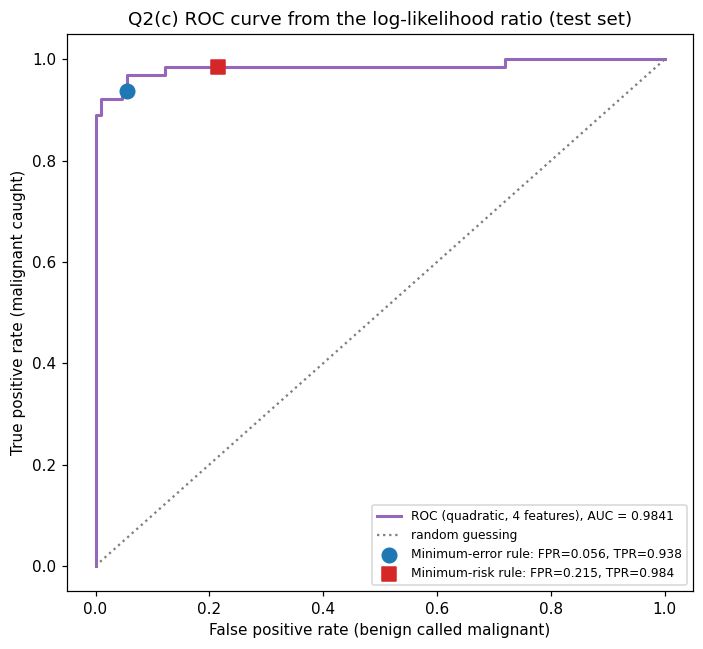

In [42]:
def roc_points(scores, y_true):
    # sweep thresholds over all distinct scores (highest first); predict malignant if score >= t
    thresholds = np.concatenate([[np.inf], np.sort(np.unique(scores))[::-1]])
    is_pos = y_true == MALIGNANT
    tpr = np.array([(scores[is_pos] >= t).mean() for t in thresholds])
    fpr = np.array([(scores[~is_pos] >= t).mean() for t in thresholds])
    return fpr, tpr


fpr, tpr = roc_points(llr_test, yc_test)
auc = np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, color="tab:purple", lw=2, label=f"ROC (quadratic, 4 features), AUC = {auc:.4f}")
ax.plot([0, 1], [0, 1], color="grey", ls=":", label="random guessing")
for name, marker, colour in [("Minimum-error rule", "o", "tab:blue"), ("Minimum-risk rule", "s", "tab:red")]:
    pt = summary_c.loc[name]
    ax.scatter(pt["FPR"], pt["TPR"], s=90, marker=marker, color=colour, zorder=5,
               label=f"{name}: FPR={pt['FPR']:.3f}, TPR={pt['TPR']:.3f}")
ax.set_xlabel("False positive rate (benign called malignant)")
ax.set_ylabel("True positive rate (malignant caught)")
ax.set_title("Q2(c) ROC curve from the log-likelihood ratio (test set)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**What the ROC curve shows.** AUC = 0.984. The log-likelihood ratio ranks almost every malignant test tumour above almost
every benign one, so the four-feature quadratic model separates the classes very well. Both rules lie on the same
curve, because they use the same score and differ only in the threshold:
* the **minimum-error point** (FPR 0.056, TPR 0.938) sits near the top-left corner,
* the **minimum-risk point** (FPR 0.215, TPR 0.984) sits further right and higher. Lowering the threshold moves us along the
  curve, buying a higher detection rate with more false alarms.

#### Class-wise training histograms with fitted univariate Gaussians
For *worst concave points* and *worst texture* we plot the training values of each class as a density histogram and
overlay a 1-D Gaussian whose mean and standard deviation (with $N_k-1$, matching `np.cov`) are estimated from that class.

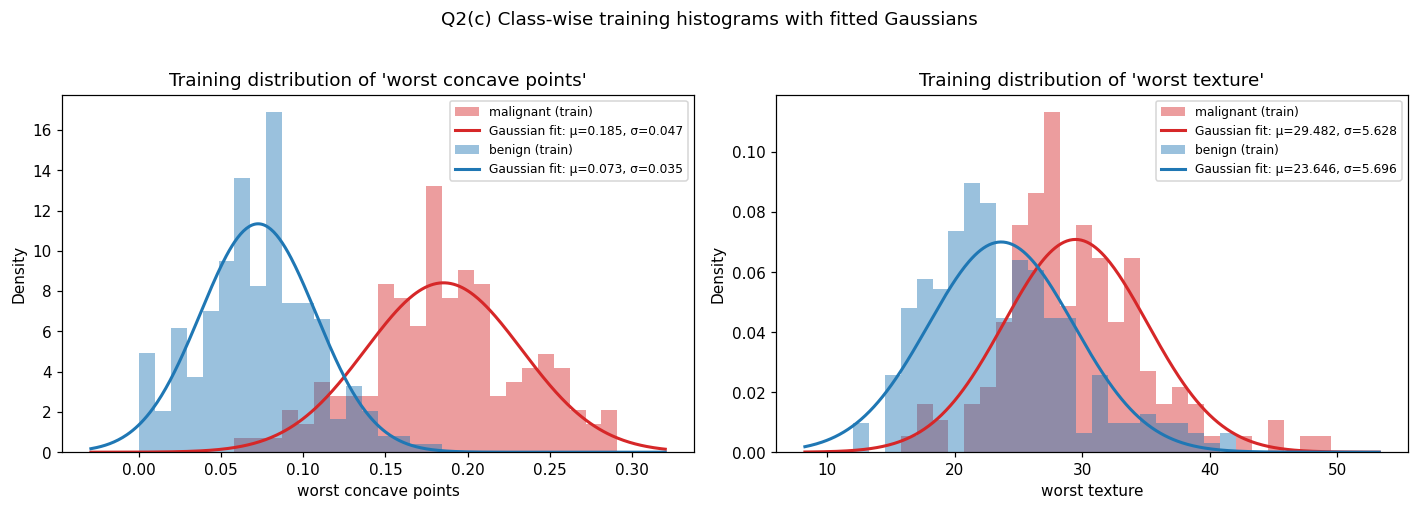

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feature in zip(axes, ["worst concave points", "worst texture"]):
    col = FEATURES_4.index(feature)
    values = Xc_train[:, col]
    bins = np.histogram_bin_edges(values, bins=30)
    x_grid = np.linspace(values.min() - 0.1 * np.ptp(values), values.max() + 0.1 * np.ptp(values), 400)
    for k in CLASS_ORDER:
        v = values[yc_train == k]
        mu, sd = v.mean(), v.std(ddof=1)
        ax.hist(v, bins=bins, density=True, alpha=0.45, color=CLASS_COLOUR[k], label=f"{CLASS_NAME[k]} (train)")
        ax.plot(x_grid, np.exp(-0.5 * ((x_grid - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)),
                color=CLASS_COLOUR[k], lw=2, label=f"Gaussian fit: μ={mu:.3f}, σ={sd:.3f}")
    ax.set_title(f"Training distribution of '{feature}'")
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)
fig.suptitle("Q2(c) Class-wise training histograms with fitted Gaussians", y=1.02)
plt.tight_layout()
plt.show()

**What the histograms show.**
* **Worst concave points** separates the classes well: benign values are centred near 0.073 and malignant near 0.185, with only
  a small overlap around 0.12–0.15. This explains why it is one of the two features used in part (b).
* **Worst texture** overlaps a lot (means 23.6 vs 29.5 with standard deviations of about 5.7 for both), so on its own it is a weak feature.
* The Gaussian fits are reasonable but not perfect. Benign concave points cannot go below 0, but the fitted curve puts some
  mass there, and the malignant texture values have a longer right tail than a Gaussian. So the Gaussian assumption is only
  approximately true. This is one reason the classifiers are not 100% accurate, even though the AUC is high.

### Question 2 – Conclusions
1. All covariance condition numbers were below $10^6$ (largest $1.40\times10^5$), so **no regularisation was applied**.
2. Both Gaussian classifiers easily beat the prior-only baseline (62.6% accuracy, every malignant tumour missed). The linear
   model had slightly higher accuracy (95.9% vs 94.2%), but the quadratic model missed fewer malignant tumours (4 vs 7).
3. Separate covariances give curved (quadratic) boundaries. A shared covariance gives straight-line boundaries. Changing
   the priors only shifts the linear boundary parallel to itself, trading missed cancers for false alarms.
4. Using a 10:1 loss lowers the likelihood-ratio threshold from 1.689 to 0.169. On the test set this cut missed malignant
   tumours from 4 to 1 and reduced the average loss from 0.269 to 0.193, at the cost of accuracy (94.2% → 86.0%) and more false
   alarms (6 → 23). When errors have different costs, **the right rule is the one that minimises expected loss, not the one
   with the highest accuracy**.